<a href="https://colab.research.google.com/github/hamptb/Engineering-w-Machine-Learning/blob/main/HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Brendan Hampton
RIN: 662055564

1. Construct a convolutional neural network model for classifying the CIFAR-10 dataset.
   Use the test set of the CIFAR-10 dataset as validation data for the model.

1) Construct a convolutional neural network model for classifying the CIFAR-10 dataset.
Use the test set of the CIFAR-10 dataset as validation data for the model

i) (64 pts.) Implement the convolutional neural network architecture given below.

a) The first layer is a 2D convolutional layer with 64 filters, each of size (5, 5),
and uses the ReLU activation function. The input shape of the layer should
correspond to the dimensions of the input image.

b) The second layer is a max pooling layer of size (2, 2).

c) The third layer is another 2D convolutional layer with 32 filters, each of size (3,
3), and uses the ReLU activation function.

d) The fourth layer is another max pooling layer of size (2, 2).

e) The fifth layer is another 2D convolutional layer with 32 filters, each of size (3,
3), and uses the ReLU activation function.

f) The sixth layer is a flattened layer which converts the output of the previous
layer into a one-dimensional vector.

g) The seventh layer is a dense layer with 64 neurons and uses the ReLU activation
function.

h) The eighth and final layer produces estimated probabilities to classify the
CIFAR-10 classes.

In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pickle

In [7]:
import os

print(os.listdir('/content'))

['.config', 'batches.meta', 'data_batch_5', 'data_batch_2', 'data_batch_3', 'data_batch_1', 'test_batch', 'data_batch_4', 'sample_data']


In [8]:
def load_batch(file):
    with open(file, 'rb') as f:
        batch = pickle.load(f, encoding='bytes')

    images = batch[b'data']
    labels = batch[b'labels']

    images = images.reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)

    return images, np.array(labels)

In [9]:
x_train_batches = []
y_train_batches = []

for i in range(1, 6):
    x, y = load_batch(f'/content/data_batch_{i}')

    x_train_batches.append(x)
    y_train_batches.append(y)

x_train = np.concatenate(x_train_batches)
y_train = np.concatenate(y_train_batches)

In [10]:
x_test, y_test = load_batch('/content/test_batch')

In [11]:
x_train_scaled = x_train.astype('float32') / 255.0
x_test_scaled = x_test.astype('float32') / 255.0

In [12]:
print("Training images:", x_train_scaled.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test_scaled.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)


In [13]:
print(x_train_scaled.min(), x_train_scaled.max())
print(x_test_scaled.min(), x_test_scaled.max())

0.0 1.0
0.0 1.0


In [14]:
model = tf.keras.models.Sequential()
model.add(
    tf.keras.layers.Conv2D(
    filters = 64,
    kernel_size = (5,5),
    activation = 'relu',
    input_shape = (32,32,3)
        )
    )
model.add(
    tf.keras.layers.MaxPool2D(
        pool_size = (2,2)
        )
    )
model.add(
    tf.keras.layers.Conv2D(
        filters = 32,
        kernel_size = (3,3),
        activation ='relu'
        )
    )
model.add(
    tf.keras.layers.MaxPool2D(
        pool_size = (2,2))
    )
model.add(
    tf.keras.layers.Conv2D(
        filters = 32,
        kernel_size = (3,3),
        activation ='relu'
        )
    )
model.add(
    tf.keras.layers.Flatten()
    )
model.add(
    tf.keras.layers.Dense(
        64,
        activation = 'relu'
        )
    )
model.add(
    tf.keras.layers.Dense(
        10,
        activation = 'softmax'
    )
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ii) (6 pts.) Calculate and plot the training and validation accuracies of the network
after 10 epochs with a batch size of 64

In [15]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(
    x_train_scaled,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test_scaled, y_test)
)
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 51s 63ms/step - accuracy: 0.3907 - loss: 1.6662 - val_accuracy: 0.4948 - val_loss: 1.3859
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 49s 63ms/step - accuracy: 0.5280 - loss: 1.3166 - val_accuracy: 0.5498 - val_loss: 1.2743
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 48s 62ms/step - accuracy: 0.5841 - loss: 1.1715 - val_accuracy: 0.5962 - val_loss: 1.1342
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 48s 62ms/step - accuracy: 0.6192 - loss: 1.0804 - val_accuracy: 0.6106 - val_loss: 1.1101
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 82s 62ms/step - accuracy: 0.6450 - loss: 1.0161 - val_accuracy: 0.6261 - val_loss: 1.0688
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 81s 61ms/step - accuracy: 0.6607 - loss: 0.9636 - val_accuracy: 0.6488 - val_loss: 1.0117
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 48s 61ms/step - accuracy: 0.6773 - loss: 0.9178 - val_accuracy: 0.6615 - val_loss: 0.9767
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 82s 61ms/step - accuracy: 0.6916 - loss: 0.8818 - 

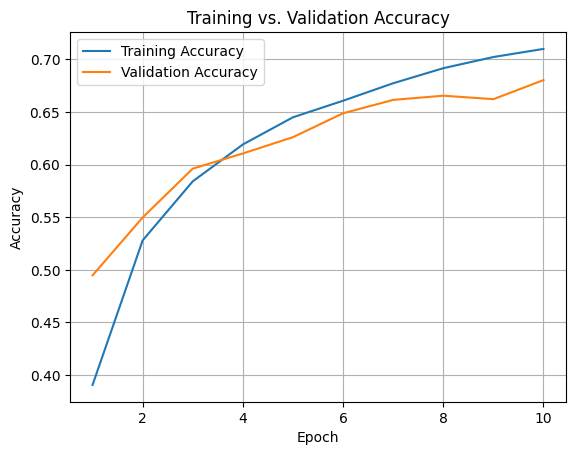

In [16]:
import matplotlib.pyplot as plt

epochs = range(1, 11)

plt.plot(epochs, train_accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs. Validation Accuracy')
plt.legend()
plt.grid()

plt.show()

2) Use the Scikit-learn breast cancer Wisconsin dataset and support vector machine classifiers
to classify breast cancers. You must use worst compactness, worst concavity, and worst
area features only to perform the classification.

i) (15 pts.) What is the accuracy of the classification model with a linear kernel?

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [19]:
cancer = load_breast_cancer()
print(cancer.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [25]:
print(cancer.feature_names.tolist().index('worst compactness'),
cancer.feature_names.tolist().index('worst concavity'),
cancer.feature_names.tolist().index('worst area'))

25 26 23


In [29]:
X = cancer.data[:, [23, 25, 26]]
y = cancer.target

In [30]:
print(X.shape)
print(y.shape)

(569, 3)
(569,)


In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [32]:
model = SVC(kernel='linear')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')

Accuracy: 0.9649122807017544


ii) (15 pts.) What is the accuracy of the classification model with a radial basis function
kernel with regularization strength parameter, C=2?

In [43]:
model = SVC(kernel='rbf', C=2)
model.fit(X_train, y_train)
y_pred_rbf = model.predict(X_test)
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
print(f'Accuracy: {accuracy_rbf}')

Accuracy: 0.9473684210526315
